# 3.6 Investigação adicional: como a velocidade de operação (`SP`) modifica os picos espectrais?

## Pergunta e justificativa

> **Como varia, entre os níveis de `SP`, a frequência do pico principal de 30 a 200 Hz? Essa variação é a mesma em hélices saudáveis e defeituosas?**

Por que vale a pena perguntar:

- **É um dos exemplos do enunciado** ("como a velocidade de operação modifica picos espectrais?").
- **A 3.3 e a 3.4 deram uma pista, mas só em três pares ilustrativos.** O maior pico sobe de ≈ 56,5 para 99 e 133,5 Hz de SP1 a SP3 na saudável, e fica um pouco abaixo na defeituosa. Falta verificar isso com todas as janelas e todos os registros.
- **A 3.4 mostrou que as amplitudes (RMS, pico) mudam de sentido conforme o `SP`.** Uma frequência pode ser uma característica mais estável que uma amplitude, e esta seção testa isso.

**O que não se afirma aqui.** A documentação pública do DronePropB confirma que a velocidade de operação variou, mas não diz a que rotação (rpm) corresponde cada `SP`, nem qual fenômeno físico gera cada pico. Então os picos são tratados só como picos do espectro, sem atribuir causa nem converter em rotação.

## Método

1. **Espectro de cada janela** de 2 s (Δf = 0,5 Hz), com a mesma função `espectro` do notebook 3 (Hann, sem a média), nas 2370 janelas.
2. **`f1` = frequência do maior pico de 30 a 200 Hz**, a mesma definição do notebook 5. A busca é restrita a essa faixa, e não feita escolhendo os maiores picos do espectro inteiro e filtrando depois (ver checklist).
3. **Problema encontrado (seção 1):** em SP1 e SP2, o maior pico salta, de uma janela para outra, entre um pico e outro com o **dobro** da frequência (≈ 53 e ≈ 106 Hz em SP1, ≈ 95 e ≈ 190 Hz em SP2). Por isso, além de `f1`, uso um **pico de base `f_base`**:
   - se existe um pico em f1/2 (± 2 Hz) com pelo menos **30%** da magnitude de `f1`, então `f_base` = esse pico;
   - senão, `f_base` = `f1`.

   É uma correção só para o caso "o maior pico é o dobro de outro pico". Na seção 4, o limiar de 30% é trocado por 20% e 50% para ver se a conclusão muda.
4. **Resumo por registro:** mediana das janelas do registro (30 ou 10 janelas). As janelas de um mesmo registro não são independentes, então as comparações usam os 99 registros, não as 2370 janelas.
5. **Comparação saudável × defeituosa** por `SP`, com a AUC do notebook 5. AUC < 0,5 significa que a frequência tende a ser menor na defeituosa.
6. **Controle da data de gravação:** os saudáveis são separados em setembro (`R1`, 2 por `SP`, mesmo mês dos defeituosos) e novembro (`R2` e `R3`, 4 por `SP`).

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.stats import mannwhitneyu

from src.freq_features import FS, espectro
from src.io_utils import DATA_DIR, ler_acc

janelas = pd.read_csv("../data/processed/janelas.csv")
registros = pd.read_csv("../results/tables/registros.csv")
assert np.isclose(registros["fs_acc"], FS).all() and (registros["fs_acc_decl"] == FS).all()

# espectro de todas as janelas, guardando só de 20 a 450 Hz (o suficiente para f1, f1/2 e 2*f1)
magnitudes = []
for arquivo, g in janelas.groupby("arquivo", sort=False):
    x = ler_acc(arquivo).astype(float)
    W = np.array([x[ini:fim] for ini, fim in zip(g["ini"], g["fim"])])
    f, mag = espectro(W, FS)
    faixa_guardada = (f >= 20) & (f <= 450)
    magnitudes.append(mag[:, faixa_guardada])
F = f[faixa_guardada]
M = np.vstack(magnitudes)

# a ordem de groupby(sort=False) é a ordem de aparição; confere que bate com a tabela de janelas
ordem = pd.concat([g for _, g in janelas.groupby("arquivo", sort=False)])
assert ordem.index.equals(janelas.index)
print("espectros:", M.shape, "| Δf =", F[1] - F[0], "Hz")

espectros: (2370, 861) | Δf = 0.5 Hz


In [2]:
def pico_de_base(F, M, limiar=0.3, fmin=30, fmax=200, tolerancia=2.0):
    # f1: maior pico de fmin a fmax; f_base: o pico em f1/2, se ele tiver >= limiar * |X(f1)|
    faixa = np.where((F >= fmin) & (F <= fmax))[0]
    i1 = faixa[M[:, faixa].argmax(axis=1)]
    f1 = F[i1]
    m1 = M[np.arange(len(M)), i1]

    f_base = f1.copy()
    for k in range(len(M)):
        perto = np.where(np.abs(F - f1[k] / 2) <= tolerancia)[0]
        if len(perto):
            j = perto[M[k, perto].argmax()]
            if M[k, j] >= limiar * m1[k]:
                f_base[k] = F[j]
    return f1, f_base


janelas["f1"], janelas["f_base"] = pico_de_base(F, M, limiar=0.3)
print(f"janelas em que f_base = f1/2: {(janelas['f_base'] != janelas['f1']).sum()} de {len(janelas)}")
print(f"janelas com f1 na borda da faixa (30 ou 200 Hz): {((janelas['f1'] <= 30.5) | (janelas['f1'] >= 199.5)).sum()}")

janelas em que f_base = f1/2: 306 de 2370
janelas com f1 na borda da faixa (30 ou 200 Hz): 26


## 1. O maior pico salta entre um pico e o seu dobro

Antes de resumir, vale olhar a distribuição de `f1` janela a janela. Se o maior pico fosse sempre o mesmo, cada `SP` teria um grupo só de valores.

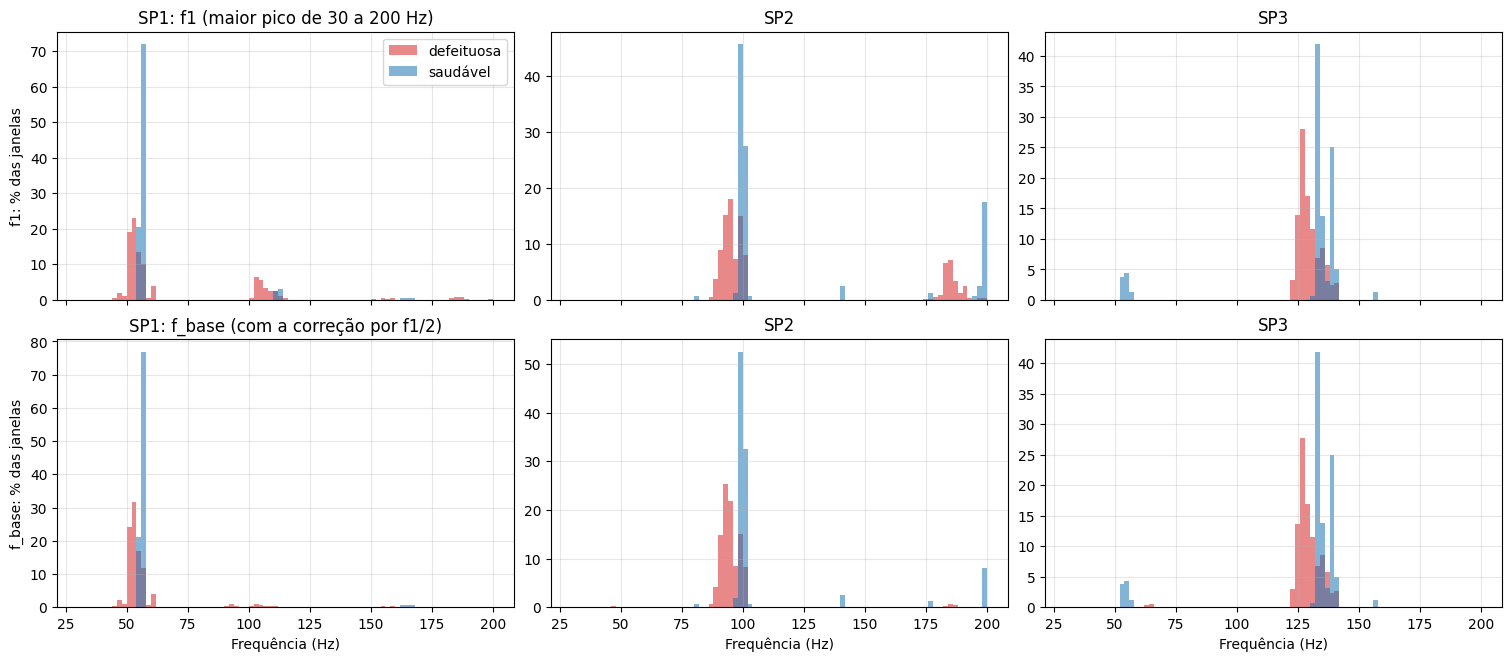

Quantis 5%, 50% e 95% por janela (Hz):
                  f1               f_base              
                0.05   0.50   0.95   0.05   0.50   0.95
SP rotulo                                              
1  defeituoso   50.5   54.0  112.0   50.5   53.0  100.8
   saudavel     55.5   56.0  111.5   55.5   56.0   57.0
2  defeituoso   90.5   97.2  187.5   90.0   94.0  101.0
   saudavel     98.0  100.0  200.0   98.0   99.5  200.0
3  defeituoso  124.5  128.0  137.8  124.5  128.0  137.8
   saudavel     54.0  133.5  140.0   54.0  133.5  140.0


In [3]:
cores = {"saudavel": "tab:blue", "defeituoso": "tab:red"}
rotulos = {"saudavel": "saudável", "defeituoso": "defeituosa"}
bins = np.arange(30, 201, 2)

fig, paineis = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True, layout="constrained")
for coluna, sp in enumerate((1, 2, 3)):
    for linha, (variavel, nome) in enumerate([("f1", "f1 (maior pico de 30 a 200 Hz)"),
                                              ("f_base", "f_base (com a correção por f1/2)")]):
        ax = paineis[linha, coluna]
        for rotulo in ("defeituoso", "saudavel"):
            v = janelas.loc[(janelas["SP"] == sp) & (janelas["rotulo"] == rotulo), variavel]
            # porcentagem dentro de cada condição, porque há 630 janelas defeituosas e 160 saudáveis por SP
            ax.hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)), color=cores[rotulo],
                    alpha=0.55, label=rotulos[rotulo])
        ax.set(title=f"SP{sp}: {nome}" if coluna == 0 else f"SP{sp}")
        ax.grid(alpha=0.3)
    paineis[1, coluna].set_xlabel("Frequência (Hz)")
for linha, nome in enumerate(["f1", "f_base"]):
    paineis[linha, 0].set_ylabel(f"{nome}: % das janelas")
paineis[0, 0].legend()
plt.savefig("../results/figures/picos_sp_histograma.png", dpi=150)
plt.show()

tab = janelas.groupby(["SP", "rotulo"])[["f1", "f_base"]].quantile([0.05, 0.5, 0.95]).unstack().round(1)
print("Quantis 5%, 50% e 95% por janela (Hz):")
print(tab.to_string())

**O que se vê.**

- **Em SP1 e SP2, `f1` tem dois grupos de valores**, um com o dobro da frequência do outro: ≈ 50–57 e ≈ 100–112 Hz em SP1, ≈ 90–101 e ≈ 180–200 Hz em SP2. Em algumas janelas, o pico mais alto é o primeiro, e em outras é o dobro dele. Em SP3, o dobro (≈ 260 Hz) fica fora da faixa de 30 a 200 Hz, então `f1` tem um grupo só.
- **Isso confirma a cautela do checklist**: a faixa de 30 a 200 Hz inclui o 2º harmônico em SP1 e SP2, e `f1` não é "a fundamental". Em SP2, 33 janelas saudáveis têm `f1` de 195 a 200 Hz, o dobro de ≈ 100 Hz. Várias estão no limite da faixa, o que indica um pico perto de 200 Hz ou logo acima.
- **Com a correção (linha de baixo), a maior parte das janelas cai no grupo mais baixo** (306 janelas corrigidas). Sobram alguns casos:
  - 44 janelas defeituosas de SP1 continuam perto de 100–110 Hz, e 13 saudáveis de SP2 (todas de `F0_SV0_SP2_C3_R2`) continuam em 200 Hz. Nelas, o pico em f1/2 tem menos de 30% da magnitude de `f1`, e a correção não se aplica.
  - 15 janelas saudáveis de SP3 ficam em ≈ 54 Hz, todas do registro `F0_SV0_SP3_C3_R2`. Ali, o maior pico de 30 a 200 Hz é um pico em ≈ 54 Hz, e não o dobro de outro.
- **Já janela a janela, os histogramas mostram o resultado principal:** em cada `SP`, a defeituosa fica um pouco à esquerda da saudável e é mais espalhada.

## 2. Estrutura dos picos no espectro médio

Espectro médio de 20 a 450 Hz por `SP` e condição, com `f_base` (mediana das janelas) e seus múltiplos marcados. Isso mostra de onde vêm os dois grupos da seção 1.

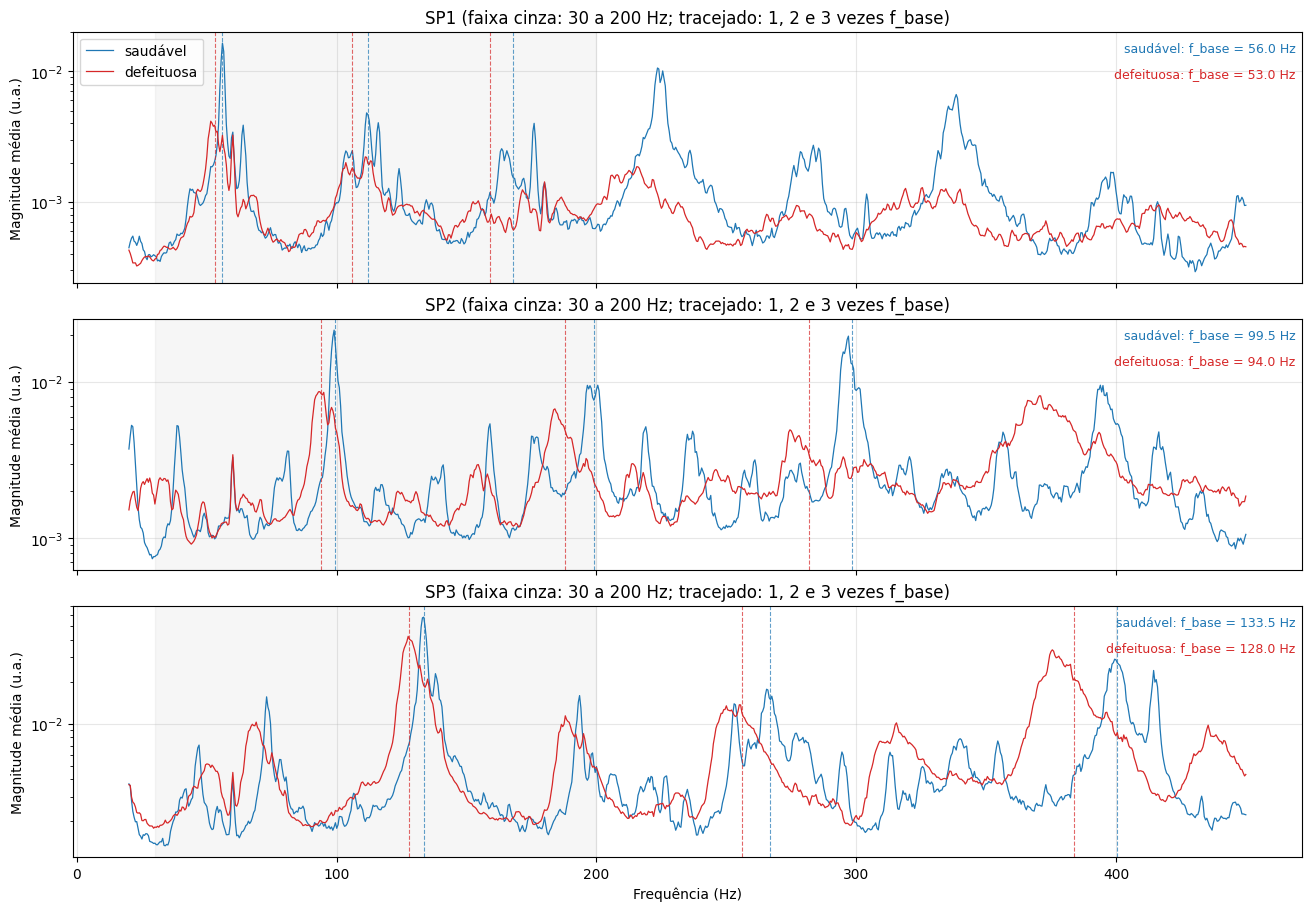

In [4]:
fig, paineis = plt.subplots(3, 1, figsize=(13, 9), sharex=True, layout="constrained")
for ax, sp in zip(paineis, (1, 2, 3)):
    for rotulo in ("saudavel", "defeituoso"):
        sel = ((janelas["SP"] == sp) & (janelas["rotulo"] == rotulo)).to_numpy()
        ax.semilogy(F, M[sel].mean(axis=0), color=cores[rotulo], lw=0.9, label=rotulos[rotulo])
        fb = janelas.loc[sel, "f_base"].median()
        for k in (1, 2, 3):
            if k * fb <= 450:
                ax.axvline(k * fb, color=cores[rotulo], ls="--", lw=0.8, alpha=0.7)
        ax.text(0.995, 0.92 - 0.1 * (rotulo == "defeituoso"), f"{rotulos[rotulo]}: f_base = {fb:.1f} Hz",
                transform=ax.transAxes, ha="right", fontsize=9, color=cores[rotulo])
    ax.axvspan(30, 200, color="gray", alpha=0.07)
    ax.set(title=f"SP{sp} (faixa cinza: 30 a 200 Hz; tracejado: 1, 2 e 3 vezes f_base)",
           ylabel="Magnitude média (u.a.)")
    ax.grid(alpha=0.3)
paineis[0].legend(loc="upper left")
paineis[-1].set_xlabel("Frequência (Hz)")
plt.savefig("../results/figures/picos_sp_espectro_medio.png", dpi=150)
plt.show()

**O que se vê.** Em cada `SP` há uma série de picos perto de 1, 2 e 3 vezes `f_base`. As linhas tracejadas caem sobre picos do espectro médio. Nem todo pico pertence à série: em SP3, por exemplo, há picos em ≈ 72 e ≈ 195 Hz que não são múltiplos de `f_base`. A série inteira se desloca para a direita quando o `SP` aumenta. Na defeituosa, a série está um pouco à esquerda e os picos são mais largos: como `f_base` varia mais entre registros e janelas defeituosos, a média espalha os picos. Não dá para dizer, só com o espectro, qual fenômeno gera essa série.

## 3. Resultado por registro

Cada ponto é a mediana das janelas de um registro. Os saudáveis estão separados por mês de gravação, e os defeituosos são todos de setembro.

In [5]:
por_registro = janelas.groupby(["arquivo", "SP", "rotulo", "F", "SV", "C"], as_index=False)[["f1", "f_base"]].median()
datas = [sio.loadmat(DATA_DIR / a, simplify_cells=True, variable_names=["AccData"])["AccData"]["DATE"]
         for a in por_registro["arquivo"]]
por_registro["mes"] = pd.to_datetime(datas, format="%d-%b-%Y").month.map({9: "setembro", 11: "novembro"})
por_registro["grupo"] = por_registro["rotulo"].map(rotulos) + " (" + por_registro["mes"] + ")"
por_registro.to_csv("../results/tables/picos_sp_registros.csv", index=False)
print(pd.crosstab([por_registro["SP"], por_registro["rotulo"]], por_registro["mes"]).to_string())

resumo = por_registro.groupby(["SP", "grupo"])["f_base"].agg(["count", "median", "min", "max"]).round(1)
print("\nf_base por registro (Hz):")
print(resumo.to_string())

mes            novembro  setembro
SP rotulo                        
1  defeituoso         0        27
   saudavel           4         2
2  defeituoso         0        27
   saudavel           4         2
3  defeituoso         0        27
   saudavel           4         2

f_base por registro (Hz):
                          count  median    min    max
SP grupo                                             
1  defeituosa (setembro)     27    53.0   47.2   60.0
   saudável (novembro)        4    56.2   56.0   56.5
   saudável (setembro)        2    56.4   56.0   56.8
2  defeituosa (setembro)     27    95.5   88.5  101.2
   saudável (novembro)        4   100.0   98.8  141.2
   saudável (setembro)        2    99.8   98.5  101.0
3  defeituosa (setembro)     27   130.2  123.5  140.2
   saudável (novembro)        4   133.2   97.0  138.0
   saudável (setembro)        2   136.8  133.5  140.0


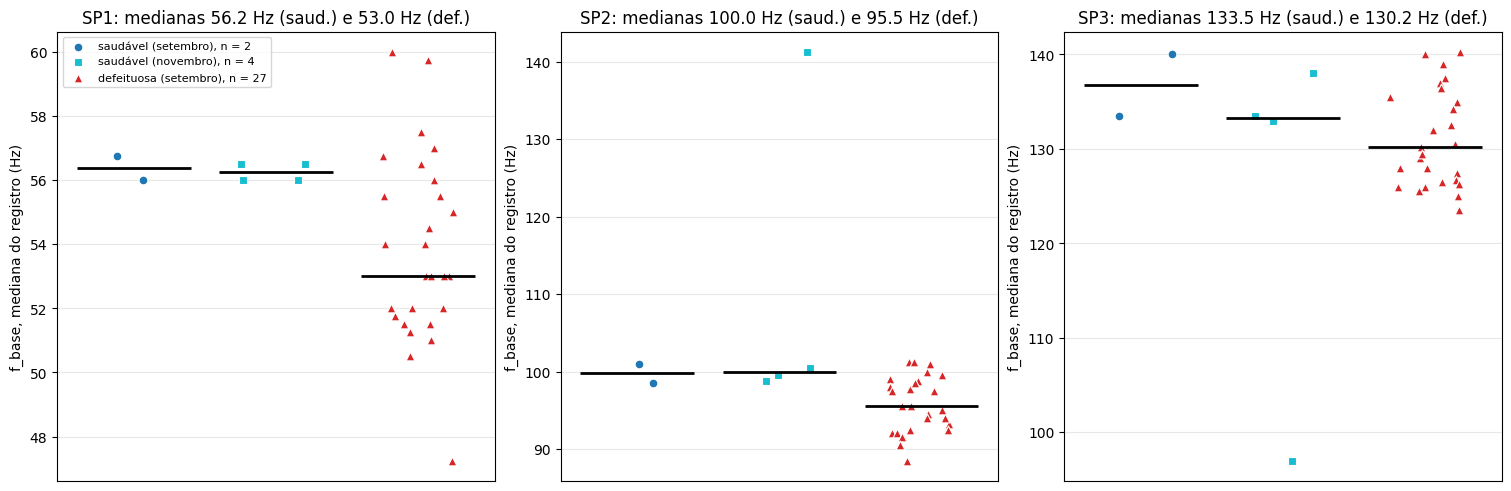

In [6]:
estilo = {"saudável (setembro)": ("tab:blue", "o", -0.2), "saudável (novembro)": ("tab:cyan", "s", 0.0),
          "defeituosa (setembro)": ("tab:red", "^", 0.2)}
rng = np.random.default_rng(0)

fig, paineis = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
for ax, sp in zip(paineis, (1, 2, 3)):
    g = por_registro[por_registro["SP"] == sp]
    for grupo, (cor, marcador, desloc) in estilo.items():
        v = g.loc[g["grupo"] == grupo, "f_base"]
        ax.scatter(desloc + rng.uniform(-0.05, 0.05, len(v)), v, color=cor, marker=marcador, s=40,
                   edgecolor="white", linewidth=0.8, label=f"{grupo}, n = {len(v)}", zorder=3)
        ax.hlines(v.median(), desloc - 0.08, desloc + 0.08, color="black", lw=2, zorder=4)
    saud = g.loc[g["rotulo"] == "saudavel", "f_base"].median()
    defe = g.loc[g["rotulo"] == "defeituoso", "f_base"].median()
    ax.set(title=f"SP{sp}: medianas {saud:.1f} Hz (saud.) e {defe:.1f} Hz (def.)",
           xticks=[], ylabel="f_base, mediana do registro (Hz)")
    ax.grid(alpha=0.3, axis="y")
paineis[0].legend(fontsize=8, loc="upper left")
plt.savefig("../results/figures/picos_sp_registros.png", dpi=150)
plt.show()

In [7]:
def auc(defe, saud):
    return mannwhitneyu(defe, saud).statistic / (len(defe) * len(saud))

linhas = []
for sp, g in por_registro.groupby("SP"):
    saud = g[g["rotulo"] == "saudavel"]
    defe = g[g["rotulo"] == "defeituoso"]
    saud_set = saud[saud["mes"] == "setembro"]
    linhas.append({
        "SP": sp,
        "saudável (Hz)": saud["f_base"].median(),
        "defeituosa (Hz)": defe["f_base"].median(),
        "diferença (%)": 100 * (defe["f_base"].median() / saud["f_base"].median() - 1),
        "AUC": auc(defe["f_base"], saud["f_base"]),
        "AUC só setembro": auc(defe["f_base"], saud_set["f_base"]),
        "defeituosas abaixo do menor saudável (%)": 100 * (defe["f_base"] < saud["f_base"].min()).mean(),
        "amplitude saudável (Hz)": saud["f_base"].max() - saud["f_base"].min(),
        "IQR defeituosa (Hz)": defe["f_base"].quantile(0.75) - defe["f_base"].quantile(0.25),
    })
comparacao = pd.DataFrame(linhas)
comparacao.round(3).to_csv("../results/tables/picos_sp_comparacao.csv", index=False)
print(comparacao.round(2).to_string(index=False))

# quanto f_base cresce de um SP para o outro (razão em relação a SP1)
medianas = por_registro.groupby(["SP", "rotulo"])["f_base"].median().unstack()
print("\nRazão f_base(SP) / f_base(SP1):")
print((medianas / medianas.loc[1]).round(3).rename(columns=rotulos).to_string())

 SP  saudável (Hz)  defeituosa (Hz)  diferença (%)  AUC  AUC só setembro  defeituosas abaixo do menor saudável (%)  amplitude saudável (Hz)  IQR defeituosa (Hz)
  1          56.25            53.00          -5.78 0.22             0.20                                     74.07                     0.75                 3.88
  2         100.00            95.50          -4.50 0.15             0.19                                     70.37                    42.75                 6.12
  3         133.50           130.25          -2.43 0.38             0.21                                      0.00                    43.00                 8.62

Razão f_base(SP) / f_base(SP1):
rotulo  defeituosa  saudável
SP                          
1            1.000     1.000
2            1.802     1.778
3            2.458     2.373


**O que se vê.**

- **`f_base` sobe com o `SP` nas duas condições:** de 56,2 para 100,0 e 133,5 Hz na saudável, e de 53,0 para 95,5 e 130,2 Hz na defeituosa (medianas por registro). A ordem SP1 < SP2 < SP3 vale para 97 dos 99 registros. As duas exceções são os saudáveis `F0_SV0_SP2_C3_R2` (141,2 Hz) e `F0_SV0_SP3_C3_R2` (97,0 Hz). Nos dois, metade das janelas está em um pico e metade em outro (seção 1), e a mediana de 30 valores cai entre os dois, num valor que nenhuma janela tem. A mediana por registro é frágil nesses casos. Os dois são `C3_R2`, gravados em novembro. Isso é coerente com a leitura de `SP` como nível de velocidade, mas o crescimento não é proporcional a 1, 2, 3: as razões em relação a SP1 são ≈ 1,8 e ≈ 2,4. Sem a rotação real, não dá para interpretar essas razões.
- **A defeituosa tem `f_base` menor nos três `SP`**: 5,8%, 4,5% e 2,4% abaixo da saudável (AUC de 0,22, 0,15 e 0,38). A diferença relativa diminui de SP1 para SP3, como a da entropia no notebook 5.
- **A saudável varia muito menos.** Em SP1, os 6 registros saudáveis ficam entre 56,0 e 56,8 Hz, enquanto os defeituosos se espalham de 47 a 60 Hz, e 74% deles ficam abaixo do menor saudável. Em SP2 são 70%. Em SP3 nenhum fica, porque o saudável de 97 Hz puxa o mínimo para baixo. Sem os dois registros com mediana entre picos, os saudáveis de SP2 e SP3 também ficam concentrados (98,5–101,0 e 133,0–140,0 Hz).
- **A data de gravação não parece explicar a diferença.** Os 2 saudáveis de setembro, o mesmo mês dos defeituosos, têm `f_base` praticamente igual aos de novembro em SP1 e SP2 (56,4 contra 56,2 Hz e 99,8 contra 100,0 Hz). Em SP3, eles ficam até acima (136,8 contra 133,2 Hz). Usando só os saudáveis de setembro, a AUC fica em 0,20, 0,19 e 0,21, com o mesmo sentido. Com 2 registros por `SP`, isso é uma verificação parcial, não uma prova. Mas é diferente da média do sinal, que no notebook 5 acompanhava a data.

### Por grupo de falha e severidade

Só os defeituosos, por grupo `F` e por severidade `SV`. São 9 registros por `F` e `SP`, e 9 por `SV` e `SP`.

f_base por F (mediana, Hz):
F       1      2      3
SP                     
1    55.5   52.0   53.0
2    97.8   92.5   95.0
3   132.0  126.8  130.5

f_base por SV (mediana, Hz):
SV      1      2      3
SP                     
1    54.0   53.0   53.0
2    95.5   97.5   94.0
3   130.5  132.0  128.0


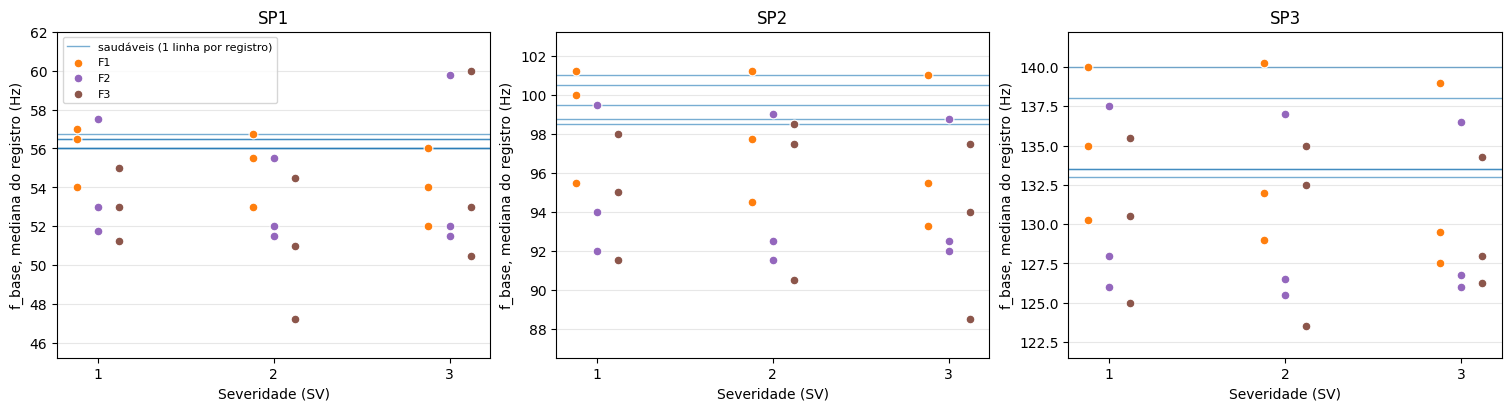

In [8]:
defeituosos = por_registro[por_registro["rotulo"] == "defeituoso"]
print("f_base por F (mediana, Hz):")
print(defeituosos.pivot_table(index="SP", columns="F", values="f_base", aggfunc="median").round(1).to_string())
print("\nf_base por SV (mediana, Hz):")
print(defeituosos.pivot_table(index="SP", columns="SV", values="f_base", aggfunc="median").round(1).to_string())

fig, paineis = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
cores_f = {1: "tab:orange", 2: "tab:purple", 3: "tab:brown"}
for ax, sp in zip(paineis, (1, 2, 3)):
    g = defeituosos[defeituosos["SP"] == sp]
    saud = por_registro[(por_registro["SP"] == sp) & (por_registro["rotulo"] == "saudavel")]["f_base"]
    # uma linha por registro saudável; o eixo segue os defeituosos, então os saudáveis com
    # mediana entre dois picos (141,2 Hz em SP2 e 97,0 Hz em SP3) ficam fora do gráfico
    for i, v in enumerate(saud):
        ax.axhline(v, color="tab:blue", lw=1, alpha=0.6, label="saudáveis (1 linha por registro)" if i == 0 else None)
    ax.set_ylim(g["f_base"].min() - 2, g["f_base"].max() + 2)
    for falha, cor in cores_f.items():
        gg = g[g["F"] == falha]
        ax.scatter(gg["SV"] + (falha - 2) * 0.12, gg["f_base"], color=cor, s=40, edgecolor="white",
                   linewidth=0.8, label=f"F{falha}", zorder=3)
    ax.set(title=f"SP{sp}", xlabel="Severidade (SV)", xticks=[1, 2, 3], ylabel="f_base, mediana do registro (Hz)")
    ax.grid(alpha=0.3, axis="y")
paineis[0].legend(fontsize=8)
plt.savefig("../results/figures/picos_sp_grupos.png", dpi=150)
plt.show()

Linhas azuis: cada registro saudável do mesmo `SP`. Os dois saudáveis com mediana entre dois picos ficam fora do eixo.

**O que se vê.** O grupo `F2` tem o `f_base` mais baixo nos três `SP` e o `F1` o mais alto, mas os grupos se sobrepõem. A severidade não mostra uma tendência monótona (SV1 → SV3). Com 3 registros por combinação de `F`, `SV` e `SP`, isso é descritivo. Como o significado de `F` e `SV` não está documentado no DronePropB, não dá para interpretar a diferença entre grupos.

## 4. A conclusão depende do estimador?

A correção por f1/2 tem um limiar (30%). Aqui, a comparação é refeita com `f1` sem correção e com limiares de 20% e 50%.

In [9]:
linhas = []
for nome, limiar in [("f1 (sem correção)", None), ("f_base, limiar 20%", 0.2),
                     ("f_base, limiar 30%", 0.3), ("f_base, limiar 50%", 0.5)]:
    f1, fb = pico_de_base(F, M, limiar=limiar if limiar else 0.3)
    valor = f1 if limiar is None else fb
    tmp = janelas[["arquivo", "SP", "rotulo"]].assign(v=valor).groupby(["arquivo", "SP", "rotulo"], as_index=False)["v"].median()
    linha = {"estimador": nome}
    for sp, g in tmp.groupby("SP"):
        saud, defe = g[g["rotulo"] == "saudavel"]["v"], g[g["rotulo"] == "defeituoso"]["v"]
        linha[f"SP{sp} saud."] = saud.median()
        linha[f"SP{sp} def."] = defe.median()
        linha[f"SP{sp} AUC"] = auc(defe, saud)
    linhas.append(linha)
sensibilidade = pd.DataFrame(linhas)
print(sensibilidade.round(2).to_string(index=False))

         estimador  SP1 saud.  SP1 def.  SP1 AUC  SP2 saud.  SP2 def.  SP2 AUC  SP3 saud.  SP3 def.  SP3 AUC
 f1 (sem correção)      56.25      55.5     0.41      100.0     97.75     0.27      133.5    130.25     0.38
f_base, limiar 20%      56.25      53.0     0.18      100.0     95.50     0.17      133.5    130.25     0.38
f_base, limiar 30%      56.25      53.0     0.22      100.0     95.50     0.15      133.5    130.25     0.38
f_base, limiar 50%      56.25      53.0     0.22      100.0     95.50     0.15      133.5    130.25     0.38


**O que se vê.** Com qualquer um dos quatro estimadores, a mediana da defeituosa fica abaixo da saudável nos três `SP` e a AUC fica abaixo de 0,5. Sem a correção, a AUC fica mais perto de 0,5 em SP1 e SP2 (0,41 e 0,27), porque os saltos para o dobro da frequência misturam os registros. Os limiares de 20%, 30% e 50% dão as mesmas medianas. A conclusão não depende do estimador, só a intensidade da separação.

## Conclusão

- **A velocidade de operação desloca a série de picos.** O pico de base de 30 a 200 Hz sobe de ≈ 56 para ≈ 100 e ≈ 133 Hz de SP1 a SP3 na saudável, e de ≈ 53 para ≈ 96 e ≈ 130 Hz na defeituosa. Isso vale para 97 dos 99 registros (as duas exceções são registros com mediana entre dois picos), e os picos em 2 e 3 vezes `f_base` acompanham o deslocamento.
- **A defeituosa tem `f_base` de 2 a 6% menor**, nos três `SP`, e é mais espalhada entre registros. Ao contrário do RMS, que muda de sentido entre os `SP` (notebook 5), esta frequência tem o mesmo sentido nos três níveis. É uma candidata natural para as características espectrais da classificação.
- **`f1`, como estava definido, é instável em SP1 e SP2**, porque salta para o dobro da frequência. Para a 2ª entrega, `f_base` é uma característica mais estável que `f1`. Ainda assim, a mediana por registro deve ser vista com cuidado nos registros com dois picos.

## Limitações

- **Nenhuma causa física é atribuída.** Não se sabe a rotação real de cada `SP`, nem por que a defeituosa tem `f_base` menor. Uma hipótese seria que a hélice defeituosa gira mais devagar com o mesmo comando, mas isso não pode ser verificado com os dados disponíveis.
- **`f_base` não é necessariamente a fundamental.** É o pico mais baixo de uma série dentro de 30 a 200 Hz. Pode haver componentes abaixo de 30 Hz, que não foram investigadas.
- **A correção por f1/2 é heurística.** Ela não corrige janelas em que o maior pico é o triplo do pico de base. A seção 4 mostra que isso não muda a conclusão.
- **Data de gravação:** a verificação com os saudáveis de setembro usa só 2 registros por `SP`.
- **Poucos registros saudáveis** (6 por `SP`), e repetições e configurações do mesmo grupo são parecidas entre si. As AUCs são descritivas.
- **A classe defeituosa mistura `F1` a `F3` e `SV1` a `SV3`**, cujos significados não estão documentados.